#### DATASET INVESTIGATION

In [1]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("train_labels.csv")

print(df["class"].nunique())
print(df["class"].unique())

print(df["image_id"].nunique())

8
<StringArray>
[  'DogEye', 'DogMouth',  'DogFace',  'DogNose',  'CatNose',  'CatFace',
 'CatMouth',   'CatEye']
Length: 8, dtype: str
63660


In [7]:
import os
from PIL import Image 

folder_path = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\train\train"

file_extension = ".jpg"

data_list = []

for filename in os.listdir(folder_path):
    if filename.lower().endswith(file_extension):
        file_path = os.path.join(folder_path, filename)
        try:
            file_size_bytes = os.path.getsize(file_path)
            file_size_mb = file_size_bytes / (1024)
            
           
            with Image.open(file_path) as img:
                width, height = img.size
            
       
            print(f"{filename:<30} | {file_size_mb:<15.2f} | {width}x{height}")
            data_list.append({
                'File Name': filename,
                'File Size (MB)': file_size_mb,
                'Width': width,
                'Height': height
            })
        except Exception as e:
            print(f"Could not process {filename}: {e}")


df = pd.DataFrame(data_list)

csv_output_path = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\animal_facial_recognition\image_size_data.csv"

df.to_csv(csv_output_path, index=False)
print(f"\nSuccessfully logged all data to {csv_output_path}")


00001.jpg                      | 1.45            | 36x36
00002.jpg                      | 23.40           | 214x157
00003.jpg                      | 6.55            | 97x97
00004.jpg                      | 5.47            | 110x110
00005.jpg                      | 1.69            | 42x42
00006.jpg                      | 1.35            | 28x28
00007.jpg                      | 14.88           | 182x135
00008.jpg                      | 6.09            | 128x128
00009.jpg                      | 90.48           | 343x376
00010.jpg                      | 1.25            | 36x36
00011.jpg                      | 10.92           | 149x148
00012.jpg                      | 4.82            | 94x70
00013.jpg                      | 3.57            | 98x68
00014.jpg                      | 21.20           | 188x182
00015.jpg                      | 13.14           | 158x158
00016.jpg                      | 11.54           | 140x140
00017.jpg                      | 2.30            | 66x66
00018.jpg    

=== FILE SIZE ===
Average: 10.61
Largest: 1233.08
Smallest: 0.64

=== IMAGE DIMENSIONS ===
Average width:  113 px
Average height: 110 px
Largest width:  2219 px
Largest height: 2219 px
Average total pixels: 22026
Largest total pixels: 4923961

=== LARGEST FILES ===
       File Size (kB)  Width  Height
8325      1233.079102   2219    2219
47667      976.843750   2190    2070
7890       780.717773   1429    1429
16819      747.480469   1791    1736
44618      742.433594   1719    1720
10529      685.170898   1623    1624
9071       643.545898   1424    1425
55653      631.757812   1383    1384
52413      628.821289   1786    1787
539        554.873047   1281    1280

=== LARGEST DIMENSIONS ===
       Width  Height  total_pixels  File Size (kB)
8325    2219    2219       4923961     1233.079102
47667   2190    2070       4533300      976.843750
2694    1873    1873       3508129      504.759766
52413   1786    1787       3191582      628.821289
16819   1791    1736       3109176      747.

C:\Users\wah31\AppData\Local\Temp\ipykernel_23808\1091523208.py:63: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0].boxplot(
C:\Users\wah31\AppData\Local\Temp\ipykernel_23808\1091523208.py:81: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(


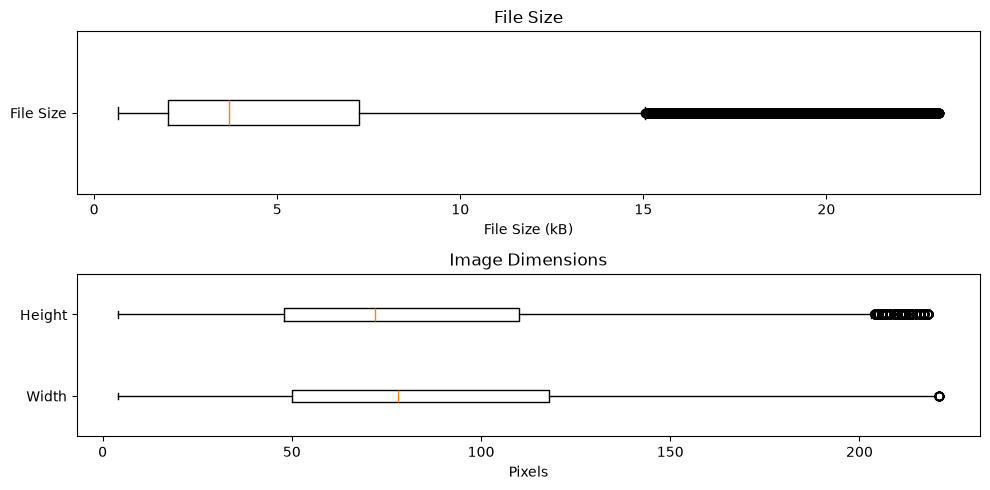

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

# Load CSV
df = pd.read_csv("image_size_data.csv")


# Summary statistics


print("=== FILE SIZE ===")
print(f"Average: {df['File Size (kB)'].mean():.2f}")
print(f"Largest: {df['File Size (kB)'].max():.2f}")
print(f"Smallest: {df['File Size (kB)'].min():.2f}")

print("\n=== IMAGE DIMENSIONS ===")
print(f"Average width:  {df['Width'].mean():.0f} px")
print(f"Average height: {df['Height'].mean():.0f} px")
print(f"Largest width:  {df['Width'].max():.0f} px")
print(f"Largest height: {df['Height'].max():.0f} px")

# Total pixels
df["total_pixels"] = df["Width"] * df["Height"]

print(f"Average total pixels: {df['total_pixels'].mean():.0f}")
print(f"Largest total pixels: {df['total_pixels'].max():.0f}")



# Largest files


print("\n=== LARGEST FILES ===")

largest_files = df.sort_values(
    by="File Size (kB)",
    ascending=False
)

print(largest_files[["File Size (kB)", "Width", "Height"]].head(10))



# Largest dimensions


print("\n=== LARGEST DIMENSIONS ===")

largest_dimensions = df.sort_values(
    by="total_pixels",
    ascending=False
)

print(largest_dimensions[["Width", "Height", "total_pixels", "File Size (kB)"]].head(10))


file_size = df["File Size (kB)"].dropna()
file_size_95 = file_size[file_size <= file_size.quantile(0.90)]

fig, axes = plt.subplots(2, 1, figsize=(10, 5))

# File size
axes[0].boxplot(
    file_size_95,
    vert=False
)

axes[0].set_title("File Size")
axes[0].set_xlabel("File Size (kB)")
axes[0].set_yticks([1])
axes[0].set_yticklabels(["File Size"])

width = df["Width"].dropna()
height = df["Height"].dropna()

width_95 = width[width <= width.quantile(0.90)]
height_95 = height[height <= height.quantile(0.90)]


# Image dimensions: width + height
axes[1].boxplot(
    [
        width_95,
        height_95
    ],
    vert=False
)

axes[1].set_title("Image Dimensions")
axes[1].set_xlabel("Pixels")
axes[1].set_yticks([1, 2])
axes[1].set_yticklabels(["Width", "Height"])


plt.tight_layout()
plt.show()